<h1 align="center">T2V · Text to Vision</h1>
<p align="center"><b>Describe a classifier in words. Get a working vision model — every weight generated, no training, no images.</b></p>
<p align="center">
<a href="https://github.com/kalidolinux-sudo/t2v-text-to-vision"><img src="https://img.shields.io/badge/GitHub-t2v--text--to--vision-181717?logo=github"></a>
<img src="https://img.shields.io/badge/agent-AMD%20TokenFactory-ED1C24">
<img src="https://img.shields.io/badge/model-T2V--1K%20(ImageNet--1k)-success">
</p>

An **agent on AMD TokenFactory** understands your request, describes every class visually and reasons about
look-alikes for classes it has never seen. A diffusion model (Tina × RPG, 49M parameters) then writes all
**274,042 weights of a ResNet-20** directly from the text.

| ImageNet-1k, 10 classes per task | **T2V-1K (from text)** | Fine-tuned on images | Share |
|---|---|---|---|
| Seen classes | **70.0%** | 72.4% | 97% |
| Classes never seen | **63.6%** | 74.1% | 86% |
| Never seen, whole groups held out | **47.5%** | 64.8% | 73% |

**How to use:** `Runtime → Run all`. A GPU is optional (`Runtime → Change runtime type → T4 GPU` makes generation much faster).
Cell 3 is the demo: type any classes and run it again. Cell 4 opens the full app on a public link.

In [1]:
#@title **1 · Setup** (a few minutes the first time)
import os, subprocess, sys, time, warnings
os.environ.update(TRANSFORMERS_VERBOSITY="error", HF_HUB_DISABLE_PROGRESS_BARS="1", TOKENIZERS_PARALLELISM="false")
warnings.filterwarnings("ignore")
REPO = "https://github.com/kalidolinux-sudo/t2v-text-to-vision"
if not os.path.isdir("/content/t2v-text-to-vision"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/t2v-text-to-vision"], check=True)
os.chdir("/content/t2v-text-to-vision")
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--root-user-action=ignore", "gradio>=4.0", "onnx", "pyarrow"], check=True)

import torch, transformers, huggingface_hub
transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()
from app import RELEASE_URL, download
CKPT = "checkpoints/t2v_1k.pt"
if not os.path.exists(CKPT):
    download(RELEASE_URL, CKPT)          # T2V-1K generator from the GitHub release (198 MB)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print(f"ready · device: {DEV}" + ("" if DEV == "cuda" else "  (CPU works; a T4 GPU is much faster)"))

ready · device: cpu  (CPU works; a T4 GPU is much faster)


In [2]:
#@title **2 · Agent key** (optional) { display-mode: "form" }
#@markdown The agent runs on **AMD TokenFactory**. Add your key as a Colab secret named `TOKENFACTORY_API_KEY`
#@markdown (🔑 icon on the left), or tick the box to paste it. Without a key everything still works offline:
#@markdown requests are split on commas and the TokenFactory descriptions and analogies stored with the model are used.
ask_for_key = False  #@param {type:"boolean"}
import os
from getpass import getpass
key = None
try:
    from google.colab import userdata
    key = userdata.get("TOKENFACTORY_API_KEY")
except Exception:
    pass
if not key and ask_for_key:
    key = getpass("AMD TokenFactory API key (press Enter to skip): ").strip()
if key:
    os.environ["TOKENFACTORY_API_KEY"] = key
os.environ.setdefault("TOKENFACTORY_BASE_URL", "https://developer.amd.com.cn/radeon/api/v1")
os.environ.setdefault("TOKENFACTORY_MODEL", "DeepSeek-V4-Flash")
del key
print("agent: AMD TokenFactory (live)" if os.environ.get("TOKENFACTORY_API_KEY") else "agent: offline (stored TokenFactory outputs)")

agent: offline (stored TokenFactory outputs)


### Generated a resnet20 with **274,042 weights** in **3.48 s** on `cpu`
Request parsed by: offline (split on commas)

| class | status | what the agent used |
|---|---|---|
| African elephant | **new — never seen in training** | looks like triceratops (50%), ox (30%), baboon (20%) · “Huge, gray elephant with very large ears shaped like the African continent.” |
| grand piano | **new — never seen in training** | looks like organ (50%), upright (30%), stage (20%) · “Large, black, glossy piano with a curved lid and long body” |
| killer whale | **new — never seen in training** | looks like submarine (40%), giant panda (30%), drake (30%) · “Black body with distinctive white patches above the eye and on the belly.” |
| pizza | known | “Round, flat base with red sauce, melted cheese, and toppings” |
| tabby | known | “Striped or blotched coat with an M on the forehead, varied colors” |
| school bus | known | “Large yellow vehicle with black lettering, rectangular windows, and a stop sign arm.” |
| strawberry | known | “Heart-shaped, bright red with tiny yellow seeds on surface” |
| golden retriever | known | “Large, with a dense, water-repellent coat of a rich golden color, ranging from light to dark gold.” |

### Accuracy on **400 real ImageNet photos**: **81.7%** (chance 12%)

African elephant: 54% · grand piano: 62% · killer whale: 86% · pizza: 82% · tabby: 92% · school bus: 98% · strawberry: 88% · golden retriever: 92%

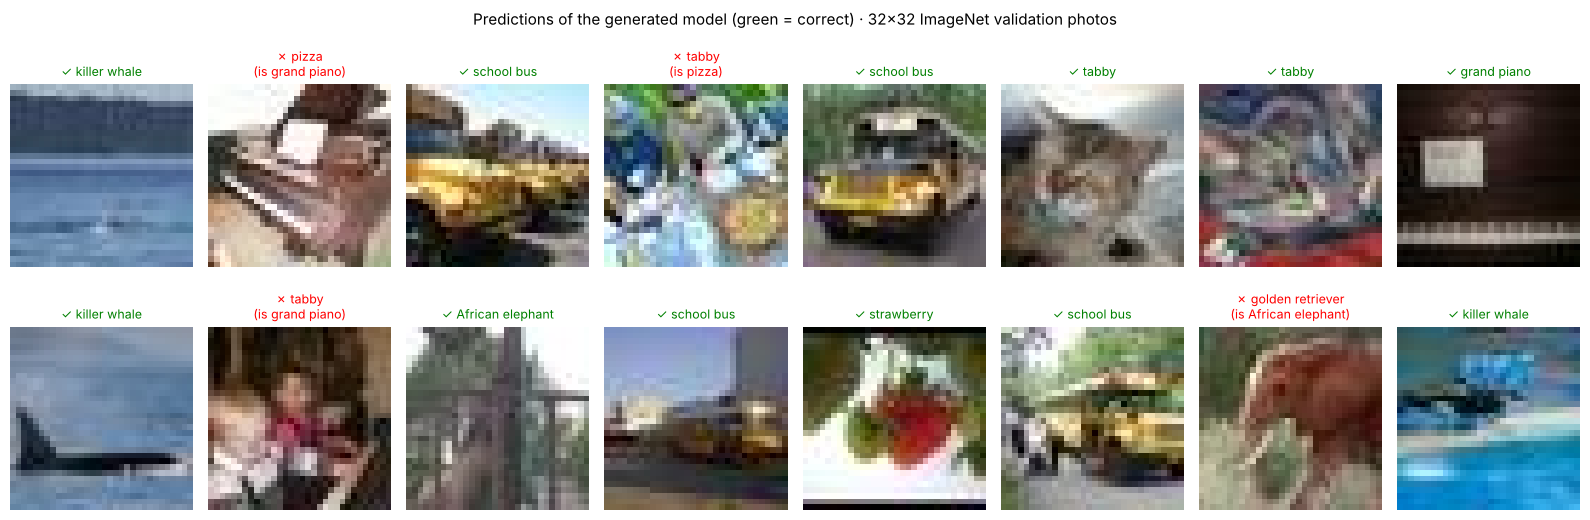

In [3]:
#@title **3 · Text → vision model → test on real ImageNet photos** { display-mode: "form" }
request = "African elephant, grand piano, killer whale, pizza, tabby, school bus, strawberry, golden retriever"  #@param {type:"string"}
#@markdown Up to 10 classes. With a TokenFactory key any language works, e.g. `أبي نموذج يميز بين الفيل والبيانو والحوت القاتل`.
#@markdown The first three default classes were **never seen in training**. This is one example task; the averages over
#@markdown 100 test tasks per row are in the table at the top.
import time, torch, numpy as np
from IPython.display import Markdown, display
from t2v.generate import load_generator, generate_flat, build_model
from t2v.llm import parse_classes
from t2v.data import _load_imagenet

if "gen" not in globals():
    gen, tok, ck = load_generator(CKPT, DEV)
classes, pinfo = parse_classes(request, tok.K)
info = {}
t0 = time.time()
flat = generate_flat(gen, tok, classes, steps=5, body_noise=0.0, gate="auto", info=info,
                     descriptions=pinfo.get("descriptions"), amp=DEV == "cuda")[0]
classes = info.get("names", classes)       # matched to the vocabulary, e.g. "African elephant"
if DEV == "cuda":
    torch.cuda.synchronize()
dt = time.time() - t0
model = build_model(ck["arch"], flat, len(classes)).to(DEV)

rows = ["| class | status | what the agent used |", "|---|---|---|"]
for c in classes:
    used = []
    if c in info.get("analogies", {}):
        used.append("looks like " + ", ".join(f"{n} ({w:.0%})" for n, w in info["analogies"][c].items()))
    if (info.get("descriptions") or {}).get(c):
        used.append(f"“{info['descriptions'][c][0]}”")
    status = "known" if info.get("known", {}).get(c, True) else "**new — never seen in training**"
    rows.append(f"| {c} | {status} | {' · '.join(used) or '—'} |")
display(Markdown(f"### Generated a {ck['arch']} with **{tok.num_params:,} weights** in **{dt:.2f} s** on `{DEV}`\n"
                 f"Request parsed by: {'offline (split on commas)' if pinfo.get('source') == 'fallback' else 'AMD TokenFactory · ' + str(pinfo.get('source'))}\n\n" + "\n".join(rows)))

# real ImageNet validation photos (50 per class, never used for training) for the classes in the vocabulary
val = _load_imagenet("test", "data", 260)
name2id = {n: i for i, n in enumerate(ck["names"])}
ids = [name2id.get(c) for c in classes]
if all(i is not None for i in ids):
    mask = torch.isin(val["y"], torch.tensor(ids))
    x, y = val["x"][mask], val["y"][mask]
    yl = torch.tensor([ids.index(int(v)) for v in y])
    with torch.no_grad():
        pred = model(x.float().div(255).to(DEV)).argmax(1).cpu()
    acc = (pred == yl).float().mean().item()
    per = {c: (pred[yl == j] == j).float().mean().item() for j, c in enumerate(classes)}
    display(Markdown(f"### Accuracy on **{len(yl)} real ImageNet photos**: **{acc:.1%}** (chance {1/len(classes):.0%})\n\n"
                     + " · ".join(f"{c}: {a:.0%}" for c, a in per.items())))
    import matplotlib.pyplot as plt
    pick = torch.randperm(len(yl), generator=torch.Generator().manual_seed(0))[:16]
    fig, axes = plt.subplots(2, 8, figsize=(16, 5.6))
    for ax, i in zip(axes.flat, pick.tolist()):
        ax.imshow(x[i].permute(1, 2, 0).numpy(), interpolation="nearest")
        ok = pred[i] == yl[i]
        ax.set_title(f"✓ {classes[pred[i]]}" if ok else f"✗ {classes[pred[i]]}\n(is {classes[yl[i]]})",
                     color="green" if ok else "red", fontsize=9)
        ax.axis("off")
    fig.suptitle("Predictions of the generated model (green = correct) · 32×32 ImageNet validation photos", fontsize=11)
    plt.tight_layout(h_pad=1.5); plt.show()
else:
    missing = [c for c, i in zip(classes, ids) if i is None]
    display(Markdown(f"*Photo test skipped: {missing} are not ImageNet-1k class names (the model was still generated).*"))

In [ ]:
#@title **4 · Open the full app** (public link, stays up while this cell runs) { display-mode: "form" }
#@markdown Click the `https://….gradio.live` link below. Stop this cell to shut the app down.
import subprocess, sys
subprocess.run([sys.executable, "app.py", "--ckpt", CKPT, "--share"])

### Links
- **Code, results, experiment log:** https://github.com/kalidolinux-sudo/t2v-text-to-vision
- **Model (T2V-1K):** https://github.com/kalidolinux-sudo/t2v-text-to-vision/releases/tag/1.0
- **Reproduce the training (72 min on a T4):** `notebooks/t2v_colab_final_imagenet.py`

Built for the AMD Developer Hackathon: ACT III · MIT license